# Листок 2. Решения

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import *
from scipy.special import gamma
from mpl_toolkits.mplot3d import Axes3D

init_printing()

x = symbols("x")


## 2.1

In [2]:
# a)
a = expand(((5 + I)*(7 - 6*I))/(3 + I))
print('a)', a, '|a|=', abs(a), 'arg=', arg(a))

# b)
b = expand((1 + I)**5 / (1 - I)**3)
print('b)', b, '|b|=', abs(b), 'arg=', arg(b))

# c)
s3 = sqrt(3)
c = expand(((-1 + I*s3)**15)/(1 - I)**20 + ((-1 - I*s3)**15)/(1 + I)**20)
print('c)', c)


a) 10 - 11*I |a|= sqrt(221) arg= -atan(11/10)
b) 2 |b|= 2 arg= 0
c) -64


## 2.2

[(-0.10235672987466886+1.0392453187359671j), (0.10235672987466886-1.0392453187359671j), (-1.0392453187359671-0.10235672987466886j), (1.0392453187359671+0.10235672987466886j), (0.6624802744001193+0.8072345499890353j), (0.8072345499890353-0.6624802744001193j), (-0.8072345499890353+0.6624802744001193j), (-0.6624802744001193-0.8072345499890353j)]


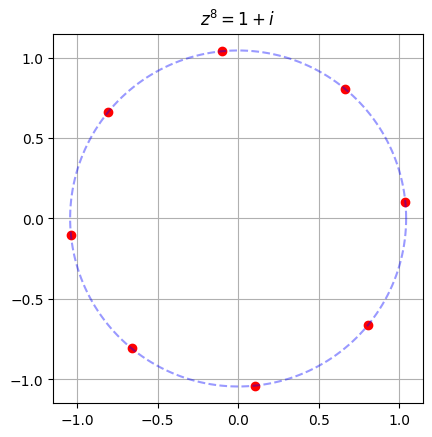

In [3]:
sols = solve(x**8 - (1 + I), x)
pts = [complex(s.evalf()) for s in sols]
print(pts)

fig, ax = plt.subplots()
ax.scatter([p.real for p in pts], [p.imag for p in pts], c='red')
theta = np.linspace(0, 2*np.pi, 200)
r = abs(pts[0])
ax.plot(r*np.cos(theta), r*np.sin(theta), 'b--', alpha=0.4)
ax.set_aspect('equal'); ax.grid(True)
ax.set_title(r'$z^8 = 1+i$')
plt.show()


## 2.3

In [4]:
def roots(w, n):
    return [complex(s.evalf()) for s in solve(x**n - w, x)]

print('a)', roots(1, 8))
print('b)', roots(-18/(1 + I*sqrt(3)), 4))
wc = expand((1-5*I)/(1+I) - 5*(1+2*I)/(2-I) + 11)
print('c)', roots(wc, 3))
print('d)', roots(1-I, 9))


a) [(-1+0j), (1+0j), -1j, 1j, (-0.7071067811865476-0.7071067811865476j), (-0.7071067811865476+0.7071067811865476j), (0.7071067811865476-0.7071067811865476j), (0.7071067811865476+0.7071067811865476j)]
b) [(-1.5-0.8660254037844386j), (1.5+0.8660254037844386j), (-0.8660254037844386+1.5j), (0.8660254037844386-1.5j)]
c) [(2.2251634906935602-0.5497593220467953j), (-1.5886872842066153-1.6521684494908837j), (-0.6364762064869448+2.201927771537679j)]
d) [(1.0353045309158533-0.09057740975216168j), (-0.596094603312291-0.8513113195501799j), (-0.4392099276035623+0.9418887293023416j), (0.7348672461377994-0.7348672461377994j), (0.8513113195501799+0.596094603312291j), (0.09057740975216168-1.0353045309158533j), (0.2689800804955465+1.0038473266333459j), (-1.0038473266333459-0.2689800804955465j), (-0.9418887293023416+0.4392099276035623j)]


## 2.4

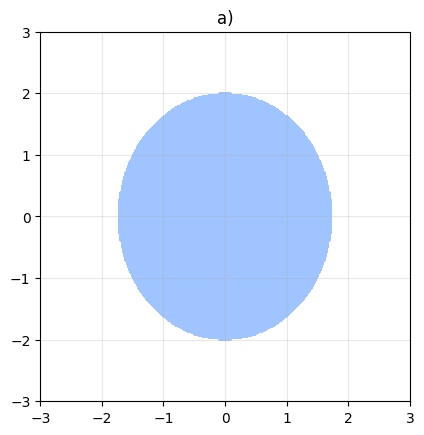

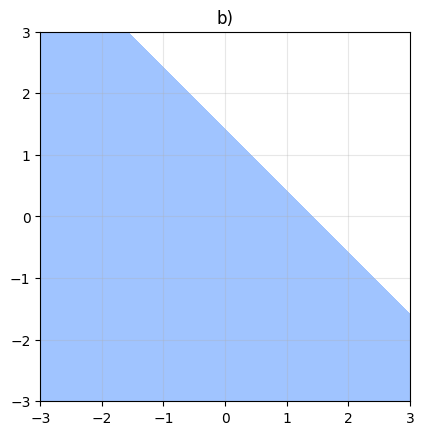

c) [(0,)]


In [5]:
def plot_mask(mask, title, lim=3, n=300):
    xx = np.linspace(-lim, lim, n)
    yy = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(xx, yy)
    Z = X + 1j*Y
    M = mask(Z)
    fig, ax = plt.subplots()
    ax.contourf(X, Y, M, levels=[0.5, 1.5], colors=['#a0c4ff'])
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
    ax.set_title(title)
    plt.show()

plot_mask(lambda Z: np.abs(Z-1j)+np.abs(Z+1j)<4, 'a)')
plot_mask(lambda Z: np.real(Z*(1-1j)) < np.sqrt(2), 'b)')

# c) точки |z+1| = |z+i| = |z-i|
# используем |w|^2 = w*conjugate(w)
z = symbols('z')
eq1 = expand((z+1)*conjugate(z+1) - (z+I)*conjugate(z+I))
eq2 = expand((z+1)*conjugate(z+1) - (z-I)*conjugate(z-I))
print('c)', solve([eq1, eq2], z))


## 2.5

In [6]:
A, u, v, C = symbols('A u v C', real=True)
B = u + I*v
print('центр:', -B/A)
print('радиус²:', simplify((abs(B)**2 - A*C)/A**2))


центр: (-u - I*v)/A
радиус²: (-A*C + u**2 + v**2)/A**2


## 2.6

сумма |z|: 11.97338446971212
max Re: 1.0806017373578454


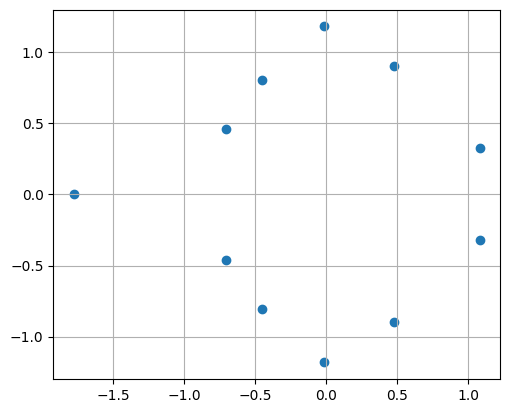

In [7]:
p = x**11 + x**10 + x**8 - 2*x**7 - x**5 + x**4 + 2*x**2 + 2*x + 2
roots = nroots(p, n=15)
print('сумма |z|:', float(sum(abs(r) for r in roots)))
print('max Re:', float(max(re(r) for r in roots)))

pts = [complex(r) for r in roots]
fig, ax = plt.subplots()
ax.scatter([p.real for p in pts], [p.imag for p in pts])
ax.set_aspect('equal'); ax.grid(True)
plt.show()


## 2.7

a) (4.36744914064015+4.8516297651578295j)
b) Arg 0.8378693695500425 48.00637865850453


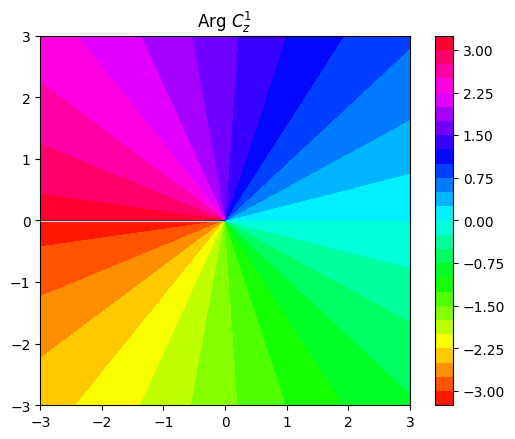

In [8]:
z, w = 1+1j, 1-1j
C = gamma(z+1)/(gamma(w+1)*gamma(z-w+1))
print('a)', C)
print('b) Arg', np.angle(C), np.degrees(np.angle(C)))

# c) линии уровня Arg(C_z^1)
nx = ny = 200
xx = np.linspace(-3, 3, nx)
yy = np.linspace(-3, 3, ny)
X, Y = np.meshgrid(xx, yy)
Z = X + 1j*Y
with np.errstate(invalid='ignore', over='ignore'):
    val = gamma(Z+1)/(gamma(2)*gamma(Z))
arg = np.angle(val)
fig, ax = plt.subplots()
im = ax.contourf(X, Y, arg, levels=30, cmap='hsv')
fig.colorbar(im)
ax.set_aspect('equal')
ax.set_title(r'Arg $C_z^1$')
plt.show()


## 2.8

In [9]:
lam = np.exp(2j*np.pi/14)
A = np.array([[7,5],[6,2]], dtype=complex)
d = np.linalg.det(A + lam*np.eye(2))
print(d.real, d.imag)


-7.26779038701949 4.686785134526054


## 2.9

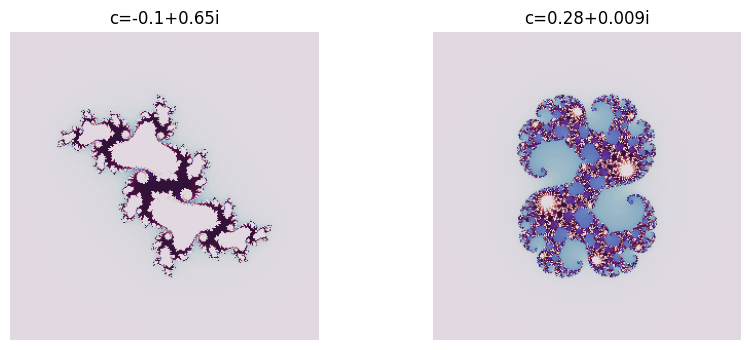

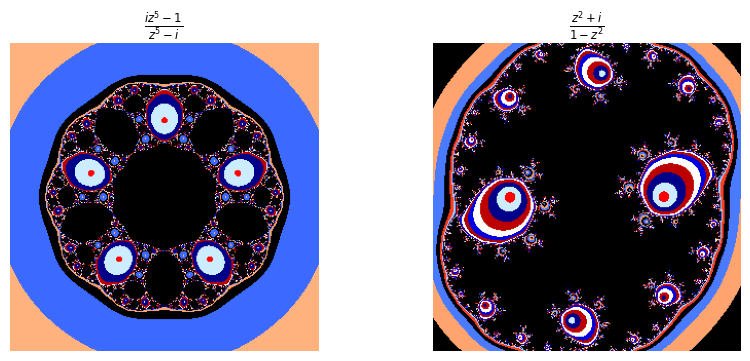

In [10]:
def julia(c, n=300, max_iter=150, z_max=10, lim=1.8):
    xx = np.linspace(-lim, lim, n)
    yy = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(xx, yy)
    Z = X + 1j*Y
    img = np.zeros(Z.shape, dtype=int)
    for i in range(max_iter):
        mask = np.abs(Z) <= z_max
        Z[mask] = Z[mask]**2 + c
        img[mask] = i
    return img

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, c, t in zip(axes, [complex(-0.1,0.65), complex(0.28,0.009)],
                    ['c=-0.1+0.65i', 'c=0.28+0.009i']):
    ax.imshow(julia(c), cmap='twilight', extent=[-1.8,1.8,-1.8,1.8], origin='lower')
    ax.set_title(t); ax.axis('off')
plt.show()

def julia_rat(f, n=300, max_iter=100, z_max=10, lim=2):
    xx = np.linspace(-lim, lim, n)
    yy = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(xx, yy)
    Z = X + 1j*Y
    img = np.zeros(Z.shape, dtype=int)
    for i in range(max_iter):
        mask = (np.abs(Z) <= z_max) & np.isfinite(Z)
        Z[mask] = f(Z[mask])
        img[mask] = i
    return img

f1 = lambda z: (1j*z**5 - 1)/(z**5 - 1j)
f2 = lambda z: (z**2 + 1j)/(1 - z**2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, f, t in zip(axes, [f1, f2], [r'$\frac{iz^5-1}{z^5-i}$', r'$\frac{z^2+i}{1-z^2}$']):
    ax.imshow(julia_rat(f), cmap='flag', extent=[-2,2,-2,2], origin='lower')
    ax.set_title(t); ax.axis('off')
plt.show()


## 2.10

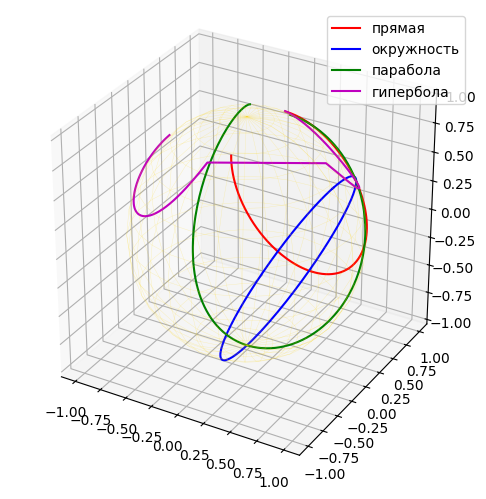

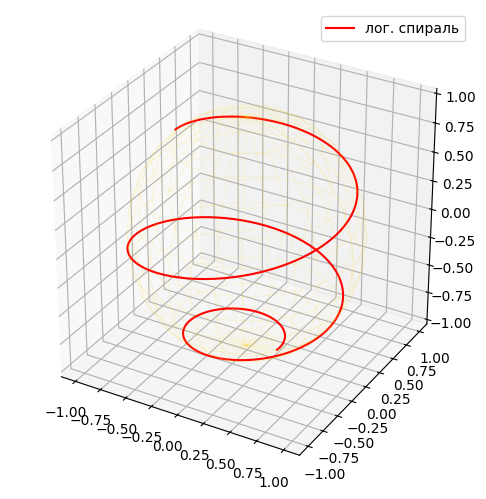

In [11]:
def stereo(z):
    x, y = np.asarray(z).real, np.asarray(z).imag
    r2 = x*x + y*y
    return 2*x/(1+r2), 2*y/(1+r2), (r2-1)/(1+r2)

def plot_sphere(curves, labels):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    u = np.linspace(0, 2*np.pi, 30)
    v = np.linspace(0, np.pi, 15)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_wireframe(xs, ys, zs, color='gold', alpha=0.25, linewidth=0.3)
    cols = ['r', 'b', 'g', 'm']
    for curve, col, lab in zip(curves, cols, labels):
        pts = np.array([stereo(z) for z in curve]).T
        ax.plot(pts[0], pts[1], pts[2], color=col, lw=1.5, label=lab)
    ax.set_box_aspect([1,1,1])
    ax.legend()
    plt.show()

t = np.linspace(-4, 4, 200)
line = 1 + 1j*t
circle = 1 + np.exp(1j*np.linspace(0, 2*np.pi, 200))
s = np.linspace(-2, 2, 200)
parab = s + 1j*s**2
s = np.linspace(0.3, 2.5, 150)
hyper = np.concatenate([s + 1j/s, -s - 1j/s])

plot_sphere([line, circle, parab, hyper],
            ['прямая', 'окружность', 'парабола', 'гипербола'])

# спираль
phi = np.linspace(0, 5*np.pi, 400)
r = 0.15 * np.exp(0.18*phi)
spiral = r * np.exp(1j*phi)
plot_sphere([spiral], ['лог. спираль'])
